# CardioFormerNet: A Unified Hybrid Deep Learning Framework for Multi-Class ECG Arrhythmia Classification Using STFT Spectrograms, Residual CNN, CBAM, and Transformer Networks

## Research Internship Project

**National Institute of Technology Warangal**

---

## Project Overview

This notebook presents the complete implementation of an automated ECG arrhythmia classification framework developed during a research internship. The proposed pipeline combines signal preprocessing, Short-Time Fourier Transform (STFT), Residual CNN, Convolutional Block Attention Module (CBAM), and Transformer Encoder to classify cardiac arrhythmias using the Chapman–Shaoxing ECG Database.

The notebook documents every stage of the experimental workflow, including dataset preparation, preprocessing, model development, evaluation, and explainability analysis.

---

## Research Workflow

ECG Signal → Preprocessing → STFT → Spectrogram Generation → Residual CNN → CBAM → Transformer Encoder → Classification → Evaluation → Explainability

# Phase 1 — Environment Setup

## Introduction

This phase prepares the execution environment required for the research project. All necessary libraries are imported, project configurations are initialized, and reproducibility settings are established before processing the ECG dataset.

A consistent execution environment ensures that experiments can be reproduced reliably throughout the project.

In [1]:
from __future__ import annotations

from pathlib import Path

import gc
import os
import random
import warnings
import platform

import numpy as np
import pandas as pd

import tensorflow as tf

## Experiment Configuration

Project parameters, preprocessing settings, model hyperparameters, and training configurations are centralized to improve readability, maintainability, and reproducibility throughout the implementation.

In [2]:
from dataclasses import dataclass
from pathlib import Path


@dataclass(frozen=True)
class ProjectConfig:
    PROJECT_NAME: str = (
        "ECG Arrhythmia Classification using STFT, CNN, "
        "Multi-Head Attention and Transformer Encoder"
    )
    VERSION: str = "2.0"
    RANDOM_SEED: int = 42
    KAGGLE_INPUT = Path("/kaggle/input")
    DATASET_ROOT = next(
    KAGGLE_INPUT.rglob(
        "a-large-scale-12-lead-electrocardiogram-database-for-arrhythmia-study-1.0.0"
        )
    )
    OUTPUT_ROOT: Path = Path("/kaggle/working")


@dataclass(frozen=True)
class DataConfig:
    SAMPLING_FREQUENCY: int = 500
    SIGNAL_LENGTH: int = 5000
    NUM_LEADS: int = 12


@dataclass(frozen=True)
class STFTConfig:
    WINDOW_SIZE: int = 256
    OVERLAP: int = 128
    FFT_SIZE: int = 512
    WINDOW: str = "hann"
    IMAGE_SIZE: tuple[int, int] = (224, 224)


@dataclass(frozen=True)
class ModelConfig:
    INPUT_SHAPE: tuple[int, int, int] = (224, 224, 1)
    NUM_CLASSES: int | None = None


@dataclass(frozen=True)
class TrainingConfig:
    BATCH_SIZE: int = 32
    EPOCHS: int = 100
    LEARNING_RATE: float = 1e-3


@dataclass(frozen=True)
class EvaluationConfig:
    VALIDATION_SIZE: float = 0.15
    TEST_SIZE: float = 0.15


@dataclass(frozen=True)
class ExperimentConfig:
    PROJECT: ProjectConfig = ProjectConfig()
    DATA: DataConfig = DataConfig()
    STFT: STFTConfig = STFTConfig()
    MODEL: ModelConfig = ModelConfig()
    TRAINING: TrainingConfig = TrainingConfig()
    EVALUATION: EvaluationConfig = EvaluationConfig()


CONFIG = ExperimentConfig()

## Reproducibility Configuration

Random seeds are fixed across the supported libraries to improve reproducibility and reduce variability between experimental runs. The available GPU devices are detected to document the computational environment used for model training.

In [3]:
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")


## Project Workspace Initialization

A structured workspace is created to organize all outputs generated during the research project. Models, figures, reports, processed datasets, and other experimental artifacts are stored in dedicated directories to improve organization and reproducibility.

In [5]:
PROJECT_NAME = "ECG Arrhythmia Classification"

DATASET_ROOT = Path("/kaggle/input/chapman_dataset")

OUTPUT_ROOT = Path("/kaggle/working/ECG_RESEARCH_RESULTS")

MODEL_DIR = OUTPUT_ROOT / "models"
CHECKPOINT_DIR = OUTPUT_ROOT / "checkpoints"
FIGURE_DIR = OUTPUT_ROOT / "figures"
REPORT_DIR = OUTPUT_ROOT / "reports"
PROCESSED_DATASET_DIR = OUTPUT_ROOT / "processed_dataset"
PREDICTION_DIR = OUTPUT_ROOT / "predictions"
GRADCAM_DIR = OUTPUT_ROOT / "gradcam"
SHAP_DIR = OUTPUT_ROOT / "shap"

DIRECTORIES = (
    MODEL_DIR,
    CHECKPOINT_DIR,
    FIGURE_DIR,
    REPORT_DIR,
    PROCESSED_DATASET_DIR,
    PREDICTION_DIR,
    GRADCAM_DIR,
    SHAP_DIR,
)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

for directory in DIRECTORIES:
    directory.mkdir(parents=True, exist_ok=True)

print(f"{PROJECT_NAME} workspace initialized successfully.")

ECG Arrhythmia Classification workspace initialized successfully.


## Environment Verification

The software environment and available computational resources are verified to ensure compatibility with the proposed deep learning pipeline. Recording this information supports transparency and reproducibility of the experimental setup.

In [6]:
import multiprocessing

print("Environment Summary")

print(f"Operating System : {platform.system()}")
print(f"Python Version   : {platform.python_version()}")
print(f"TensorFlow       : {tf.__version__}")
print(f"NumPy            : {np.__version__}")
print(f"CPU Cores        : {multiprocessing.cpu_count()}")
print(f"GPU Count        : {len(gpus)}")

if gpus:
    print(f"GPU              : {gpus[0].name}")

print(f"Random Seed      : {SEED}")


Environment Summary
Operating System : Linux
Python Version   : 3.12.13
TensorFlow       : 2.20.0
NumPy            : 2.0.2
CPU Cores        : 4
GPU Count        : 2
GPU              : /physical_device:GPU:0
Random Seed      : 42


# Phase 2 — Dataset Understanding

## Introduction

Before preprocessing the ECG signals, it is important to understand how the Chapman–Shaoxing ECG Database is organized. This phase explores the dataset structure, verifies the available resources, and identifies the files required for subsequent processing.

Understanding the dataset organization helps ensure that all ECG recordings, metadata, and diagnosis information are accessed correctly throughout the research project.

---

## Objectives

- Explore the dataset directory structure.
- Verify the availability of ECG recordings and metadata.
- Identify the files required for preprocessing and model development.

---

## Expected Outcome

A clear understanding of the dataset organization and confirmation that all required files are available for further processing.

In [7]:
DATASET_ROOT = CONFIG.PROJECT.DATASET_ROOT

for item in sorted(DATASET_ROOT.iterdir()):
    item_type = "Directory" if item.is_dir() else "File"
    print(f"{item.name:<35} {item_type}")

print(f"\nDataset Root : {DATASET_ROOT}")
print("Dataset verification completed successfully.")

ConditionNames_SNOMED-CT.csv        File
LICENSE.txt                         File
RECORDS                             File
SHA256SUMS.txt                      File
WFDBRecords                         Directory

Dataset Root : /kaggle/input/datasets/jashwanthakula78900/chapman-dataset/a-large-scale-12-lead-electrocardiogram-database-for-arrhythmia-study-1.0.0
Dataset verification completed successfully.


### Dataset Structure Summary

The dataset structure was inspected to verify the availability of the resources required for the subsequent research workflow.

- **WFDBRecords/** stores the raw ECG recordings.
- **RECORDS** contains the index of the available ECG files.
- **ConditionNames_SNOMED-CT.csv** provides the diagnosis-code mapping.
- Additional files contain dataset documentation and supporting information.

This verified structure is used in the subsequent record indexing and metadata extraction stages.

# Phase 3 — Dataset Indexing

## Introduction

The Chapman–Shaoxing ECG Database contains thousands of ECG recordings organized in the WFDB format. Before extracting metadata or processing signals, every available record must be indexed to establish a structured view of the dataset.

This phase creates a complete inventory of all ECG recordings that will be used throughout the research project.

---

## Objectives

- Locate all ECG recordings.
- Build an index of available records.
- Verify the total number of recordings.

---

## Expected Outcome

A complete list of ECG records ready for metadata extraction and signal preprocessing.

In [8]:
records_file = CONFIG.PROJECT.DATASET_ROOT / "RECORDS"

with records_file.open("r") as file:
    record_dirs = [line.strip() for line in file if line.strip()]

print(f"Indexed Directories : {len(record_dirs)}")
print("\nFirst 10 Indexed Directories:\n")

for directory in record_dirs[:10]:
    print(directory)

all_records = []

for directory in record_dirs:
    folder = CONFIG.PROJECT.DATASET_ROOT / directory

    for hea_file in folder.glob("*.hea"):
        record_name = hea_file.stem
        mat_file = folder / f"{record_name}.mat"

        all_records.append({
            "record_id": record_name,
            "hea_path": hea_file,
            "mat_path": mat_file
        })

print(f"\nTotal ECG Records : {len(all_records)}")

print("\nFirst 10 ECG Records:\n")

for record in all_records[:10]:
    print(record["record_id"])

Indexed Directories : 452

First 10 Indexed Directories:

WFDBRecords/01/010/
WFDBRecords/01/011/
WFDBRecords/01/012/
WFDBRecords/01/013/
WFDBRecords/01/014/
WFDBRecords/01/015/
WFDBRecords/01/016/
WFDBRecords/01/017/
WFDBRecords/01/018/
WFDBRecords/01/019/

Total ECG Records : 45152

First 10 ECG Records:

JS00010
JS00084
JS00071
JS00005
JS00090
JS00051
JS00037
JS00077
JS00039
JS00066


In [9]:
record_index_path = REPORT_DIR / "record_index.csv"

pd.DataFrame(all_records).to_csv(record_index_path, index=False)

print(f"Record index saved to: {record_index_path}")

Record index saved to: /kaggle/working/ECG_RESEARCH_RESULTS/reports/record_index.csv


### Dataset Index Summary

The indexing procedure identified the ECG recordings listed in the Chapman–Shaoxing database record index.

Each indexed record contains:

- A unique record identifier.
- The corresponding WFDB header file.
- The associated ECG signal file.

The resulting record index provides structured access to the ECG recordings used in subsequent metadata extraction and signal preprocessing.

# Phase 4 — Metadata Extraction

## Introduction

Each ECG recording in the Chapman–Shaoxing ECG Database is accompanied by a WFDB header file (`.hea`) containing recording metadata and diagnostic annotations. This phase parses these header files to extract the information required for dataset organization, preprocessing, and subsequent diagnosis mapping.

---

## Objectives

- Parse the WFDB header files associated with the ECG recordings.
- Extract recording and patient metadata, including lead count, sampling frequency, signal length, age, and sex.
- Extract the diagnostic SNOMED-CT codes and available clinical metadata from the header annotations.
- Organize the extracted information into a structured metadata representation.

---

## Expected Outcome

A structured metadata table containing the essential recording information and diagnostic codes for each ECG record, providing the metadata required for subsequent preprocessing and clinical label assignment.

## Header Parser Implementation

The following parser reads each WFDB header file and extracts the recording metadata and diagnostic annotations into a structured dictionary for subsequent dataset processing.

In [10]:
def parse_header(header_path):
    metadata = {
        "record_id": None,
        "num_leads": None,
        "sampling_frequency": None,
        "signal_length": None,
        "age": None,
        "sex": None,
        "diagnosis_codes": None,
        "rx": None,
        "hx": None,
        "sx": None,
    }

    with open(header_path, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    
    first = lines[0].split()

    metadata["record_id"] = first[0]
    metadata["num_leads"] = int(first[1])
    metadata["sampling_frequency"] = int(first[2])

    
    if len(first) > 3 and first[3].isdigit():
        metadata["signal_length"] = int(first[3])

    
    for line in lines:
        if not line.startswith("#"):
            continue

        key, value = line[1:].split(":", 1)
        key = key.strip().lower()
        value = value.strip()

        if key == "age":
            try:
                metadata["age"] = int(value)
            except (ValueError, TypeError):
                metadata["age"] = None
        elif key == "sex":
            metadata["sex"] = value

        elif key == "dx":
            metadata["diagnosis_codes"] = [
                int(code.strip())
                for code in value.split(",")
            ]

        elif key == "rx":
            metadata["rx"] = value

        elif key == "hx":
            metadata["hx"] = value

        elif key == "sx":
            metadata["sx"] = value

    return metadata

In [11]:
sample_metadata = parse_header(all_records[0]["hea_path"])

for key, value in sample_metadata.items():
    print(f"{key:<22}: {value}")

record_id             : JS00010
num_leads             : 12
sampling_frequency    : 500
signal_length         : 5000
age                   : 47
sex                   : Female
diagnosis_codes       : [426177001]
rx                    : Unknown
hx                    : Unknown
sx                    : Unknown


### Metadata Summary

The parsed header information provides the recording identifier, signal dimensions, sampling frequency, demographic information, and available diagnostic annotations. These metadata fields are used in the subsequent stages of dataset preparation and diagnosis label mapping.

# Phase 5 — Metadata Dataset Construction

## Objective

The metadata extracted from the ECG header files is consolidated into a structured dataset containing recording-level information such as patient demographics, recording parameters, and diagnosis codes.

## Tasks

* Construct the metadata DataFrame from the extracted ECG records.
* Standardize the metadata representation.
* Save the consolidated metadata for subsequent processing.

## Output

A structured metadata dataset containing one entry for each ECG recording.


In [13]:
import pandas as pd

metadata_records = []

for record in all_records:
    metadata_records.append(parse_header(record["hea_path"]))

metadata_df = pd.DataFrame(metadata_records)
metadata_df["age"] = metadata_df["age"].astype("Int64")

print(f"Total ECG Records : {len(metadata_df)}")
print(f"Number of Columns : {metadata_df.shape[1]}")

display(metadata_df.head())

Total ECG Records : 45152
Number of Columns : 10


,record_id,num_leads,sampling_frequency,signal_length,age,sex,diagnosis_codes,rx,hx,sx
0,JS00010,12,500,5000.0,47,Female,[426177001],Unknown,Unknown,Unknown
1,JS00084,12,500,5000.0,54,Male,"[426177001, 55827005]",Unknown,Unknown,Unknown
2,JS00071,12,500,5000.0,76,Female,"[164889003, 698252002, 55827005, 428750005]",Unknown,Unknown,Unknown
3,JS00005,12,500,5000.0,73,Female,"[164890007, 429622005, 428750005]",Unknown,Unknown,Unknown
4,JS00090,12,500,5000.0,88,Male,"[426177001, 270492004, 284470004, 55827005]",Unknown,Unknown,Unknown


In [14]:
metadata_path = REPORT_DIR / "metadata.csv"

metadata_df.to_csv(metadata_path, index=False)

print(f"Metadata saved to: {metadata_path}")

Metadata saved to: /kaggle/working/ECG_RESEARCH_RESULTS/reports/metadata.csv


In [15]:
metadata_df.describe(include="all").to_csv(
    REPORT_DIR / "metadata_summary.csv"
)

In [17]:
import ast
import re

def clean_codes(x):
    if not isinstance(x, list):
        return []

    if len(x) == 1 and isinstance(x[0], str):
        try:
            x = ast.literal_eval(x[0])
        except Exception:
            pass

    cleaned = []

    for code in x:
        code = str(code)

        code = re.sub(r"[\[\]'\"\s]", "", code)

        if code:
            cleaned.append(code)

    return cleaned

metadata_df["diagnosis_codes"] = metadata_df["diagnosis_codes"].apply(clean_codes)

# Phase 6 — SNOMED-CT Diagnosis Mapping

## Objective

The SNOMED-CT diagnosis codes associated with each ECG recording are mapped to standardized clinical abbreviations and diagnosis names using the official mapping provided with the Chapman–Shaoxing ECG Database.

## Tasks

* Load the official SNOMED-CT diagnosis mapping.
* Identify and resolve duplicate diagnosis entries.
* Map diagnosis codes to clinical abbreviations and diagnosis names.
* Generate a primary diagnosis label for each ECG recording.
* Verify the coverage of the available diagnosis-code mapping.

## Output

An enriched metadata dataset containing interpretable diagnosis labels for subsequent dataset preparation and classification.


In [19]:
# Cell 6.1 — Load Official SNOMED-CT Mapping

mapping_path = DATASET_ROOT / "ConditionNames_SNOMED-CT.csv"
mapping_df = pd.read_csv(mapping_path)
mapping_df = mapping_df.rename(columns={
    "Snomed_CT": "snomed_code",
    "Acronym Name": "acronym",
    "Full Name": "full_name"
})
mapping_df["snomed_code"] = (
    mapping_df["snomed_code"]
    .astype(str)
    .str.strip()
)
print(mapping_df.head())

  acronym                                  full_name snomed_code
0    1AVB            1 degree atrioventricular block   270492004
1    2AVB            2 degree atrioventricular block   195042002
2   2AVB1  2 degree atrioventricular block(Type one)    54016002
3   2AVB2  2 degree atrioventricular block(Type two)    28189009
4    3AVB            3 degree atrioventricular block    27885002


In [20]:
# Cell 6.2 — Duplicate Analysis
duplicate_rows = mapping_df[
    mapping_df.duplicated(
        subset="snomed_code",
        keep=False
    )
].sort_values("snomed_code")

duplicate_summary = (
    duplicate_rows
    .groupby("snomed_code")
    .size()
    .reset_index(name="Occurrences")
)
print("DUPLICATE ANALYSIS")
print(f"Duplicate SNOMED Codes : {len(duplicate_summary)}")
print(f"Duplicate Rows         : {len(duplicate_rows)}")
if len(duplicate_rows):
    display(duplicate_summary)
    display(duplicate_rows)

else:

    print("No duplicate SNOMED codes found.")

DUPLICATE ANALYSIS
Duplicate SNOMED Codes : 4
Duplicate Rows         : 12


,snomed_code,Occurrences
0,164865005,5
1,164909002,3
2,195101003,2
3,698252002,2


,acronym,full_name,snomed_code
26,MI,myocardial infarction,164865005
27,MIBW,myocardial infraction in back wall,164865005
28,MIFW,Myocardial infgraction in the front wall,164865005
29,MILW,Myocardial infraction in the lower wall,164865005
30,MISW,Myocardial infraction in the side wall,164865005
19,LBBB,left bundle branch block,164909002
20,LBBBB,left back bundle branch block,164909002
21,LFBBB,left front bundle branch block,164909002
50,WAVN,Wandering in the atrioventricalualr node,195101003
62,SAAWR,Sinus Atrium to Atrial Wandering Rhythm,195101003


In [21]:
# Cell 6.3 — Resolve Duplicates & Build Lookup Dictionaries
mapping_df = (
    mapping_df
    .drop_duplicates(
        subset="snomed_code",
        keep="first"
    )
    .reset_index(drop=True)
)
code_to_acronym = dict(
    zip(
        mapping_df["snomed_code"],
        mapping_df["acronym"]
    )
)
code_to_name = dict(
    zip(
        mapping_df["snomed_code"],
        mapping_df["full_name"]
    )
)
print("LOOKUP DICTIONARIES")
print(f"Unique SNOMED Codes : {len(code_to_acronym)}")
print(f"Acronym Dictionary  : {len(code_to_acronym)}")
print(f"Name Dictionary     : {len(code_to_name)}")

LOOKUP DICTIONARIES
Unique SNOMED Codes : 55
Acronym Dictionary  : 55
Name Dictionary     : 55


In [22]:
# Cell 6.4 - Unique Code Coverage
dataset_codes = sorted({
    code
    for codes in metadata_df["diagnosis_codes"]
    for code in codes
})
mapped_codes = [c for c in dataset_codes if c in code_to_acronym]
unmapped_codes = [c for c in dataset_codes if c not in code_to_acronym]
coverage = len(mapped_codes) / len(dataset_codes) * 100
print("UNIQUE CODE COVERAGE")
print(f"Unique Codes in Dataset : {len(dataset_codes)}")
print(f"Mapped Codes            : {len(mapped_codes)}")
print(f"Unmapped Codes          : {len(unmapped_codes)}")
print(f"Coverage                : {coverage:.2f}%")

UNIQUE CODE COVERAGE
Unique Codes in Dataset : 94
Mapped Codes            : 51
Unmapped Codes          : 43
Coverage                : 54.26%


In [23]:
# Cell 6.5 — Generate Diagnosis Labels
metadata_df["diagnosis_acronyms"] = (
    metadata_df["diagnosis_codes"]
    .apply(
        lambda codes: [
            code_to_acronym.get(code, "UNKNOWN")
            for code in codes
        ]
    )
)
metadata_df["diagnosis_names"] = (
    metadata_df["diagnosis_codes"]
    .apply(
        lambda codes: [
            code_to_name.get(code, "UNKNOWN")
            for code in codes
        ]
    )
)
metadata_df["n_diagnoses"] = (
    metadata_df["diagnosis_codes"]
    .str.len()
)
print("DIAGNOSIS LABEL GENERATION")
print(f"Metadata Shape : {metadata_df.shape}")
display(
    metadata_df[
        [
            "record_id",
            "diagnosis_codes",
            "diagnosis_acronyms",
            "diagnosis_names",
            "n_diagnoses"
        ]
    ].head()
)

DIAGNOSIS LABEL GENERATION
Metadata Shape : (45152, 13)


,record_id,diagnosis_codes,diagnosis_acronyms,diagnosis_names,n_diagnoses
0,JS00010,[426177001],[SB],[Sinus Bradycardia],1
1,JS00084,"[426177001, 55827005]","[SB, UNKNOWN]","[Sinus Bradycardia, UNKNOWN]",2
2,JS00071,"[164889003, 698252002, 55827005, 428750005]","[AFIB, IDC, UNKNOWN, STTC]","[Atrial Fibrillation, Interior differences con...",4
3,JS00005,"[164890007, 429622005, 428750005]","[AF, STDD, STTC]","[Atrial Flutter, ST drop down, ST-T Change]",3
4,JS00090,"[426177001, 270492004, 284470004, 55827005]","[SB, 1AVB, APB, UNKNOWN]","[Sinus Bradycardia, 1 degree atrioventricular ...",4


In [24]:
# Cell 6.6 - Primary Label Creation
metadata_df["primary_label"] = metadata_df["diagnosis_acronyms"].apply(
    lambda x: x[0] if len(x) else "UNKNOWN"
)
print("PRIMARY LABELS CREATED")
print(metadata_df["primary_label"].value_counts().head(20))

PRIMARY LABELS CREATED
primary_label
SB         15807
SR          7882
AF          5609
ST          5383
UNKNOWN     2267
AFIB        1779
SA          1294
APB          975
TWC          897
SVT          663
STE          401
IDC          364
ARS          301
STDD         275
1AVB         233
AT           209
TWO          119
QTIE         110
RVH           89
LVQRSAL       75
Name: count, dtype: int64


In [25]:
# Cell 6.7 - Dataset Summary

known_records = (metadata_df["primary_label"] != "UNKNOWN").sum()
unknown_records = (metadata_df["primary_label"] == "UNKNOWN").sum()


print("FINAL LABEL SUMMARY")

print(f"Total Records     : {len(metadata_df)}")
print(f"Labeled Records   : {known_records}")
print(f"Unknown Records   : {unknown_records}")
print(f"Total Classes     : {metadata_df['primary_label'].nunique()}")

display(metadata_df.head())

FINAL LABEL SUMMARY
Total Records     : 45152
Labeled Records   : 42885
Unknown Records   : 2267
Total Classes     : 39


,record_id,num_leads,sampling_frequency,signal_length,age,sex,diagnosis_codes,rx,hx,sx,diagnosis_acronyms,diagnosis_names,n_diagnoses,primary_label
0,JS00010,12,500,5000.0,47,Female,[426177001],Unknown,Unknown,Unknown,[SB],[Sinus Bradycardia],1,SB
1,JS00084,12,500,5000.0,54,Male,"[426177001, 55827005]",Unknown,Unknown,Unknown,"[SB, UNKNOWN]","[Sinus Bradycardia, UNKNOWN]",2,SB
2,JS00071,12,500,5000.0,76,Female,"[164889003, 698252002, 55827005, 428750005]",Unknown,Unknown,Unknown,"[AFIB, IDC, UNKNOWN, STTC]","[Atrial Fibrillation, Interior differences con...",4,AFIB
3,JS00005,12,500,5000.0,73,Female,"[164890007, 429622005, 428750005]",Unknown,Unknown,Unknown,"[AF, STDD, STTC]","[Atrial Flutter, ST drop down, ST-T Change]",3,AF
4,JS00090,12,500,5000.0,88,Male,"[426177001, 270492004, 284470004, 55827005]",Unknown,Unknown,Unknown,"[SB, 1AVB, APB, UNKNOWN]","[Sinus Bradycardia, 1 degree atrioventricular ...",4,SB


# Phase 7 — Dataset Preparation and Class Selection

## Objective

Prepare the metadata for supervised learning by removing records without valid diagnosis labels, consolidating diagnosis categories, encoding the selected classes, and generating the final metadata dataset.

## Tasks

* Remove records with unknown diagnosis labels.
* Analyze the diagnosis-class distribution.
* Consolidate diagnosis labels into the selected classification classes.
* Encode the final classes numerically.
* Save the prepared metadata for subsequent ECG signal processing.

## Output

A filtered metadata dataset containing the selected diagnosis classes and numerical labels for model development.


In [26]:
# Cell 7.1 - Remove records without valid diagnosis labels.

filtered_metadata = metadata_df[
    metadata_df["primary_label"] != "UNKNOWN"
].copy()


print("UNKNOWN LABEL FILTERING")

print(f"Original Records : {len(metadata_df)}")
print(f"Remaining Records: {len(filtered_metadata)}")
print(f"Removed Records  : {len(metadata_df)-len(filtered_metadata)}")

UNKNOWN LABEL FILTERING
Original Records : 45152
Remaining Records: 42885
Removed Records  : 2267


In [27]:
# Cell 7.2 - Analyze the distribution of diagnosis classes.

class_distribution = (
    filtered_metadata["primary_label"]
    .value_counts()
    .sort_values(ascending=False)
)


print("CLASS DISTRIBUTION")


display(class_distribution.to_frame(name="Samples"))

CLASS DISTRIBUTION


,Samples
primary_label,
SB,15807
SR,7882
AF,5609
ST,5383
AFIB,1779
SA,1294
APB,975
TWC,897
SVT,663


In [28]:
#Cell 7.3 - Label Mapping
CLASS_MAPPING = {
    "AF": "AFIB",
    "AFIB": "AFIB",
    "SB": "SB",
    "SR": "SR",
    "SI": "SR",
    "SVT": "GSVT",
    "AT": "GSVT",
    "ST": "GSVT",
    "AVRT": "GSVT",
    "AVNRT": "GSVT",
    "SAAWR": "GSVT",
    "WAP": "GSVT"
}

filtered_metadata["final_class"] = (
    filtered_metadata["primary_label"].map(CLASS_MAPPING)
)

filtered_metadata = filtered_metadata[
    filtered_metadata["final_class"].notna()
].copy()
print(filtered_metadata["final_class"].value_counts())

final_class
SB      15807
SR       7882
AFIB     7388
GSVT     6279
Name: count, dtype: int64


In [29]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

filtered_metadata["label"] = label_encoder.fit_transform(
    filtered_metadata["final_class"]
)

num_classes = len(label_encoder.classes_)

print("Classes:")
print(label_encoder.classes_)

print(f"\nNumber of Classes : {num_classes}")

display(
    filtered_metadata[
        ["final_class", "label"]
    ].drop_duplicates().sort_values("label")
)

Classes:
['AFIB' 'GSVT' 'SB' 'SR']

Number of Classes : 4


,final_class,label
2,AFIB,0
17,GSVT,1
0,SB,2
5,SR,3


In [30]:
# Cell 7.5 - Save MetaData.

output_path = PROCESSED_DATASET_DIR / "filtered_metadata.csv"
filtered_metadata.to_csv(
    output_path,
    index=False
)

print("Phase 7 Completed Successfully")
print(f"Filtered metadata saved to : {output_path}")
print(f"Total Samples : {len(filtered_metadata)}")

Phase 7 Completed Successfully
Filtered metadata saved to : /kaggle/working/ECG_RESEARCH_RESULTS/processed_dataset/filtered_metadata.csv
Total Samples : 37356


# Phase 8 — ECG Signal Preprocessing and STFT Spectrogram Generation

## Objective

Convert the filtered 12-lead ECG recordings into standardized time–frequency representations using the Short-Time Fourier Transform (STFT).

## Tasks

* Configure the STFT parameters.
* Load and preprocess ECG signals.
* Generate normalized spectrograms for all 12 leads.
* Build the TensorFlow data pipeline for on-the-fly spectrogram generation.
* Verify tensor dimensions and numerical validity.

## Output

A TensorFlow input pipeline that generates standardized 12-channel STFT spectrograms for model training and evaluation.


In [40]:
# Phase 8.1 - STFT Spectrogram Generation
from scipy.signal import stft
from scipy.ndimage import zoom
from scipy.io import loadmat
import numpy as np
import os

FS = 500
IMG_SIZE = 224
WINDOW = "hann"
NPERSEG = 512
NOVERLAP = 256
MAX_WORKERS = min(12, os.cpu_count())

print("STFT Configuration")
print(f"Sampling Frequency : {FS}")
print(f"Image Size         : {IMG_SIZE}")
print(f"Window             : {WINDOW}")
print(f"Window Length      : {NPERSEG}")
print(f"Overlap            : {NOVERLAP}")
print(f"Workers            : {MAX_WORKERS}")

STFT Configuration
Sampling Frequency : 500
Image Size         : 224
Window             : hann
Window Length      : 512
Overlap            : 256
Workers            : 4


In [42]:
from pathlib import Path
record_path_map = {}
for folder in record_dirs:
    folder = DATASET_ROOT / folder

    for mat_file in folder.glob("*.mat"):

        record_path_map[mat_file.stem] = mat_file

print(f"Indexed {len(record_path_map)} ECG records.")

Indexed 45152 ECG records.


Record ID       : JS00010
ECG Shape       : (5000, 12)
Sampling Rate   : 500
Duration        : 10.0 seconds


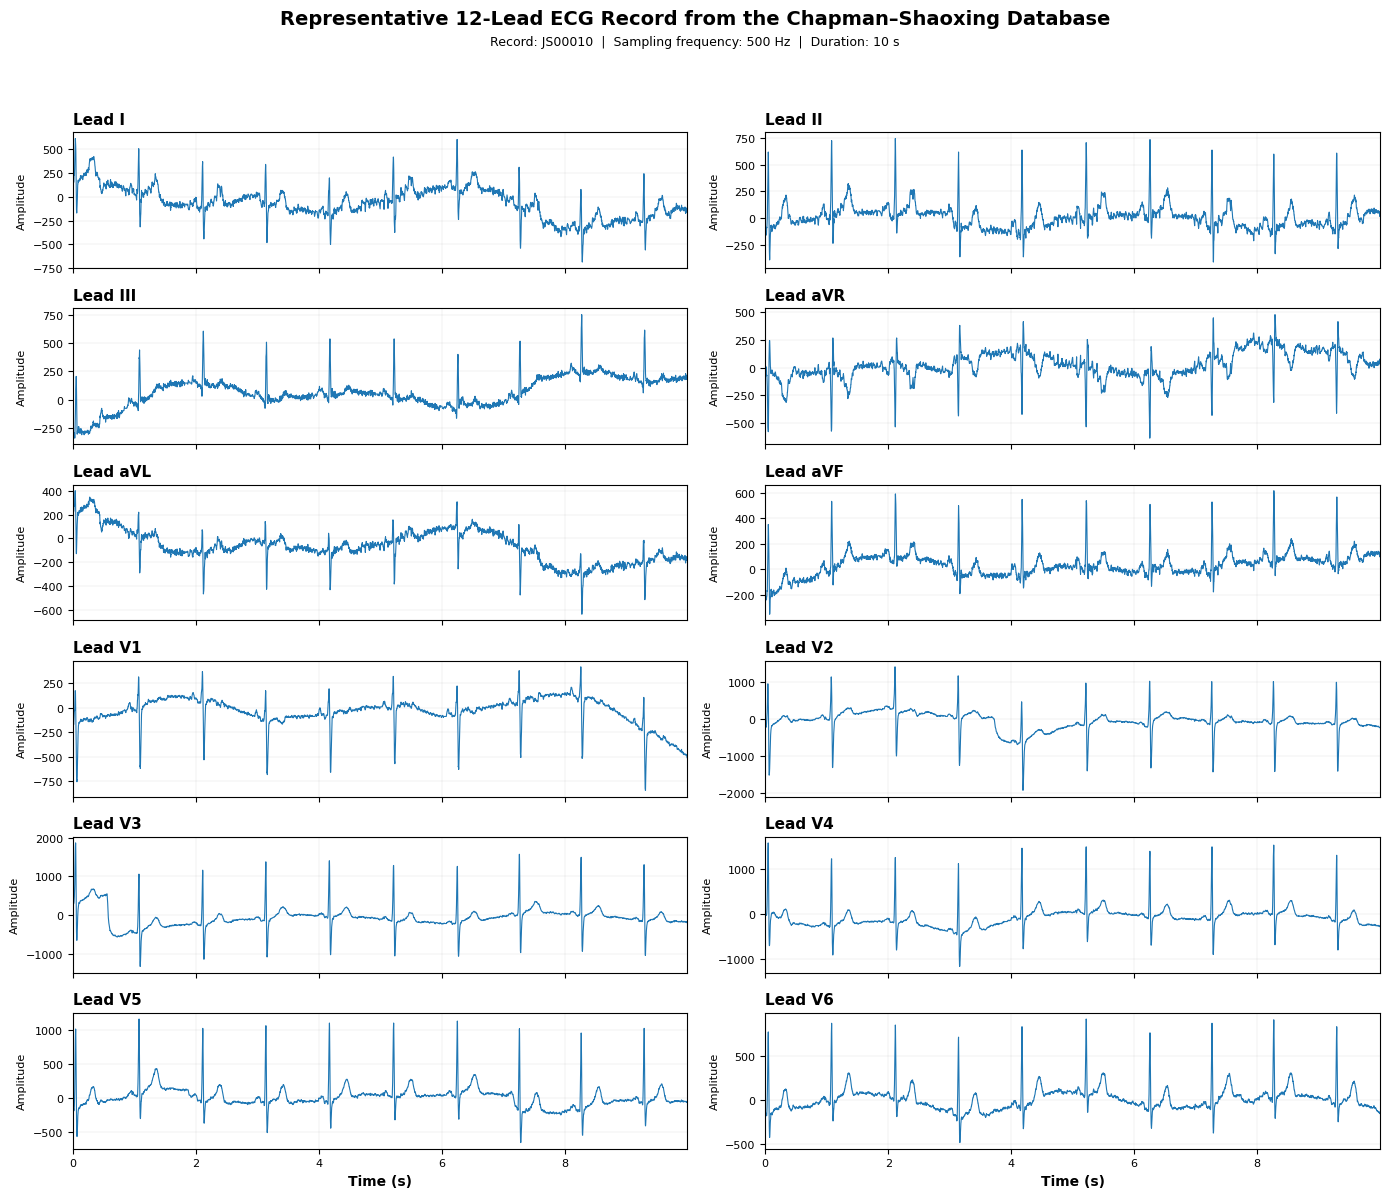


Figure saved to:
/kaggle/working/Figure1_Representative_12Lead_ECG.png


In [47]:
import matplotlib.pyplot as plt
from scipy.io import loadmat
import numpy as np


record_id = filtered_metadata.iloc[0]["record_id"]
mat_path = record_path_map[record_id]

ecg_signal = loadmat(mat_path)["val"].T.astype(np.float32)

print("Record ID       :", record_id)
print("ECG Shape       :", ecg_signal.shape)
print("Sampling Rate   :", FS)
print("Duration        :", ecg_signal.shape[0] / FS, "seconds")


lead_names = [
    "I", "II", "III", "aVR",
    "aVL", "aVF", "V1", "V2",
    "V3", "V4", "V5", "V6"
]


time = np.arange(ecg_signal.shape[0]) / FS

fig, axes = plt.subplots(
    6, 2,
    figsize=(14, 12),
    sharex=True
)

axes = axes.flatten()

for i, ax in enumerate(axes):

    ax.plot(
        time,
        ecg_signal[:, i],
        linewidth=0.8
    )

    ax.set_title(
        f"Lead {lead_names[i]}",
        fontsize=11,
        fontweight="bold",
        loc="left"
    )

    ax.set_xlim(time[0], time[-1])
    ax.grid(
        True,
        linewidth=0.35,
        alpha=0.35
    )

    ax.tick_params(
        labelsize=8
    )
    ax.set_ylabel(
        "Amplitude",
        fontsize=8
    )

axes[-2].set_xlabel(
    "Time (s)",
    fontsize=10,
    fontweight="bold"
)

axes[-1].set_xlabel(
    "Time (s)",
    fontsize=10,
    fontweight="bold"
)

fig.suptitle(
    "Representative 12-Lead ECG Record from the Chapman–Shaoxing Database",
    fontsize=14,
    fontweight="bold",
    y=0.995
)

fig.text(
    0.5,
    0.965,
    f"Record: {record_id}  |  Sampling frequency: 500 Hz  |  Duration: 10 s",
    ha="center",
    fontsize=9
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

figure1_ecg_path = "/kaggle/working/Figure1_Representative_12Lead_ECG.png"

plt.savefig(
    figure1_ecg_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nFigure saved to:")
print(figure1_ecg_path)

In [44]:
def process_lead(ecg):

    ecg = np.asarray(ecg, dtype=np.float32)

    ecg = np.nan_to_num(
        ecg,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    mean = ecg.mean()
    std = ecg.std()

    if std < 1e-8:
        return np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.float32)

    ecg = (ecg - mean) / std

    _, _, Zxx = stft(
        ecg,
        fs=FS,
        window=WINDOW,
        nperseg=NPERSEG,
        noverlap=NOVERLAP,
        boundary=None,
        padded=False
    )

    spec = np.abs(Zxx)

    spec = np.log1p(spec)

    spec = zoom(
        spec,
        (
            IMG_SIZE / spec.shape[0],
            IMG_SIZE / spec.shape[1]
        ),
        order=1
    )

    spec -= spec.min()

    mx = spec.max()

    if mx > 0:
        spec /= mx

    return spec.astype(np.float32)

In [45]:
def generate_spectrogram(record_id):

    mat_path = record_path_map[record_id]

    signal = loadmat(mat_path)["val"].T.astype(np.float32)

    spectrograms = np.stack(
        [process_lead(signal[:, lead]) for lead in range(signal.shape[1])],
        axis=-1
    )
    
    return spectrograms

In [46]:
sample = generate_spectrogram(
    filtered_metadata.iloc[0]["record_id"]
)
print("STFT Verification")
print("Shape :", sample.shape)
print("Type  :", sample.dtype)
print("Min   :", sample.min())
print("Max   :", sample.max())
print("Mean  :", sample.mean())

STFT Verification
Shape : (224, 224, 12)
Type  : float32
Min   : 0.0
Max   : 1.0
Mean  : 0.019354993


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
sample = sample.astype(np.float32)
print("Spectrogram shape:", sample.shape)
lead_names = [
    "Lead I", "Lead II", "Lead III", "Lead aVR",
    "Lead aVL", "Lead aVF", "Lead V1", "Lead V2",
    "Lead V3", "Lead V4", "Lead V5", "Lead V6"
]
vmin = np.percentile(sample, 2)
vmax = np.percentile(sample, 98)
fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(
    3, 5,
    width_ratios=[1, 1, 1, 1, 0.08],
    wspace=0.18,
    hspace=0.28
)
axes = []
for row in range(3):
    for col in range(4):
        axes.append(fig.add_subplot(gs[row, col]))
for i, ax in enumerate(axes):

    im = ax.imshow(
        sample[:, :, i],
        origin="lower",
        aspect="auto",
        cmap="inferno",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(
        lead_names[i],
        fontsize=16,
        fontweight="bold",
        pad=8
    )

    ax.tick_params(
        axis="both",
        labelsize=9
    )

fig.supxlabel(
    "Time",
    fontsize=14,
    fontweight="bold",
    y=0.035
)

fig.supylabel(
    "Frequency",
    fontsize=14,
    fontweight="bold",
    x=0.035
)

cbar_ax = fig.add_subplot(gs[:, 4])

cbar = fig.colorbar(
    im,
    cax=cbar_ax
)

cbar.set_label(
    "STFT Magnitude",
    fontsize=13,
    fontweight="bold",
    labelpad=10
)

cbar.ax.tick_params(
    labelsize=9
)

output_path = "/kaggle/working/STFT_12Lead_Spectrogram_Fig4.png"

plt.savefig(
    output_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved to:")
print(output_path)

In [38]:
from sklearn.model_selection import train_test_split
TEST_SIZE = 0.20
train_df, test_df = train_test_split(
    filtered_metadata,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=filtered_metadata["final_class"],
    shuffle=True
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print("Train/Test Split")
print(f"Training Samples : {len(train_df)}")
print(f"Testing Samples  : {len(test_df)}")
print(f"Classes          : {len(label_encoder.classes_)}")

Train/Test Split
Training Samples : 29884
Testing Samples  : 7472
Classes          : 4


In [39]:
# Phase 8.2 - Parallel STFT Dataset Generation
import tensorflow as tf
import math
import numpy as np
AUTOTUNE = tf.data.AUTOTUNE
train_size = len(train_df)
BATCH_SIZE = 32
print("TensorFlow Data Pipeline")
print(f"Training Samples : {train_size}")
print(f"Batch Size       : {BATCH_SIZE}")
print(f"Steps / Epoch    : {math.ceil(train_size/BATCH_SIZE)}")

TensorFlow Data Pipeline
Training Samples : 29884
Batch Size       : 32
Steps / Epoch    : 934


In [40]:
failed_records = []
def load_sample(record_id, label):
    record_id = record_id.decode("utf-8")
    try:
        image = generate_spectrogram(record_id)
        if np.isnan(image).any():
            raise ValueError("NaN detected")
        if np.isinf(image).any():
            raise ValueError("Inf detected")
    except Exception as e:
        print(f"\nSkipping : {record_id}")
        print(e)
        failed_records.append(record_id)
        image = np.zeros(
            (
                IMG_SIZE,
                IMG_SIZE,
                12
            ),
            dtype=np.float32
        )
    return image, np.int32(label)

In [41]:
def tf_loader(record_id, label):

    image, label = tf.numpy_function(
        load_sample,
        [record_id, label],
        [tf.float32, tf.int32]
    )

    image.set_shape(
        (
            IMG_SIZE,
            IMG_SIZE,
            12
        )
    )

    label.set_shape(())

    label = tf.one_hot(label, depth=num_classes)

    return image, label

In [42]:
@tf.function
def augment_spectrogram(image, label):

    image = tf.image.random_contrast(
        image,
        lower=0.95,
        upper=1.05
    )

    image = tf.clip_by_value(image, 0.0, 1.0)

    return image, label

In [43]:
train_dataset = (
    tf.data.Dataset.from_tensor_slices(
        (
            train_df["record_id"].astype(str).values,
            train_df["label"].values
        )
    )
    .shuffle(
        buffer_size=4096,
        reshuffle_each_iteration=True
    )
    .map(
        tf_loader,
        num_parallel_calls=AUTOTUNE,
        deterministic=False
    )
    .map(
        augment_spectrogram,
        num_parallel_calls=AUTOTUNE
    )
    .batch(
        BATCH_SIZE,
        drop_remainder=True
    )
    .prefetch(
        AUTOTUNE
    )
)

I0000 00:00:1786280500.303985      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786280500.307073      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [44]:
test_dataset = (
    tf.data.Dataset.from_tensor_slices(
        (
            test_df["record_id"].astype(str).values,
            test_df["label"].values
        )
    )
    .map(
        tf_loader,
        num_parallel_calls=AUTOTUNE,
        deterministic=False
    )
    .batch(
        BATCH_SIZE
    )
    .prefetch(
        AUTOTUNE
    )
)

In [46]:
#Phase 8.3- Tensor Verification
print("Loading Sample Batch...")
X, y = next(iter(train_dataset))

print(f"Batch Shape    : {X.shape}")
print(f"Label Shape    : {y.shape}")
print(f"Tensor Type    : {X.dtype}")

print(f"Minimum Value  : {tf.reduce_min(X).numpy():.6f}")
print(f"Maximum Value  : {tf.reduce_max(X).numpy():.6f}")
print(f"Mean Value     : {tf.reduce_mean(X).numpy():.6f}")
print(f"Std Deviation  : {tf.math.reduce_std(X).numpy():.6f}")

print(f"Sample Label   : {y[0].numpy()}")

Loading Sample Batch...
Batch Shape    : (32, 224, 224, 12)
Label Shape    : (32, 4)
Tensor Type    : <dtype: 'float32'>
Minimum Value  : 0.000000
Maximum Value  : 1.000000
Mean Value     : 0.044473
Std Deviation  : 0.110750
Sample Label   : [0. 0. 1. 0.]


In [50]:
print("Failed Records")
print("Failed Samples :", len(failed_records))
if failed_records:
    print("\nFirst 20 Failed Records\n")
    for record in failed_records[:20]:
        print(record)

Failed Records
Failed Samples : 0


# Phase 9 — Hybrid CNN–Transformer Model Development

## Objective

Develop the proposed hybrid deep learning architecture for ECG arrhythmia classification by integrating a Residual CNN backbone, CBAM attention, and Transformer Encoder blocks.

## Tasks

- Configure the model hyperparameters.
- Implement Residual CNN blocks.
- Integrate CBAM attention.
- Add positional embeddings and Transformer Encoder blocks.
- Build and compile the complete classification model.
- Verify and visualize the final architecture.

## Output

A compiled Hybrid CNN–CBAM–Transformer model ready for training in Phase 10.

## Phase 9.1: Import Deep Learning Components



In [52]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
print("TensorFlow Version :", tf.__version__)


TensorFlow Version : 2.20.0


## Phase 9.2: Model Configuration


In [53]:
INPUT_SHAPE = (224, 224, 12)
NUM_CLASSES = len(label_encoder.classes_)
EMBED_DIM = 256
NUM_HEADS = 8
FF_DIM = 512
NUM_TRANSFORMER_BLOCKS = 4
DROPOUT_RATE = 0.20
WEIGHT_DECAY = 5e-4
print("MODEL CONFIGURATION")

print(f"Input Shape        : {INPUT_SHAPE}")
print(f"Classes            : {NUM_CLASSES}")
print(f"Embedding Dim      : {EMBED_DIM}")
print(f"Attention Heads    : {NUM_HEADS}")
print(f"Transformer Blocks : {NUM_TRANSFORMER_BLOCKS}")

MODEL CONFIGURATION
Input Shape        : (224, 224, 12)
Classes            : 4
Embedding Dim      : 256
Attention Heads    : 8
Transformer Blocks : 4


## Phase 9.3: Residual Block

In [54]:
def residual_block(x, filters, stride=1):
    shortcut = x
    x = layers.Conv2D(
        filters,
        3,
        strides=stride,
        padding="same",
        kernel_regularizer=l2(WEIGHT_DECAY)
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.ReLU()(x)

    x = layers.Conv2D(
        filters,
        3,
        padding="same",
        kernel_regularizer=l2(WEIGHT_DECAY)
    )(x)

    x = layers.BatchNormalization()(x)

    if stride != 1 or shortcut.shape[-1] != filters:

        shortcut = layers.Conv2D(
            filters,
            1,
            strides=stride,
            padding="same"
        )(shortcut)

        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([x, shortcut])

    x = layers.ReLU()(x)

    return x

## Phase 9.4: CBAM Attention Module

In [55]:
def cbam_block(inputs, reduction_ratio=8):

    channels = inputs.shape[-1]
    avg_pool = layers.GlobalAveragePooling2D()(inputs)
    max_pool = layers.GlobalMaxPooling2D()(inputs)

    shared_dense_1 = layers.Dense(
        channels // reduction_ratio,
        activation="gelu"
    )

    shared_dense_2 = layers.Dense(channels)

    avg_out = shared_dense_2(shared_dense_1(avg_pool))
    max_out = shared_dense_2(shared_dense_1(max_pool))

    channel_attention = layers.Add()([avg_out, max_out])
    channel_attention = layers.Activation("sigmoid")(channel_attention)
    channel_attention = layers.Reshape((1, 1, channels))(channel_attention)

    x = layers.Multiply()([inputs, channel_attention])

    avg_pool = layers.Lambda(
        lambda z: tf.reduce_mean(z, axis=-1, keepdims=True)
    )(x)

    max_pool = layers.Lambda(
        lambda z: tf.reduce_max(z, axis=-1, keepdims=True)
    )(x)

    concat = layers.Concatenate(axis=-1)([avg_pool, max_pool])

    spatial_attention = layers.Conv2D(
        filters=1,
        kernel_size=7,
        padding="same",
        activation="sigmoid"
    )(concat)

    output = layers.Multiply()([x, spatial_attention])

    return output

## Phase 9.5: CNN Backbone

In [56]:
data_augmentation = tf.keras.Sequential([
    layers.RandomTranslation(0.01, 0.01),
    layers.RandomZoom(0.03),
])

In [57]:
inputs = tf.keras.Input(shape=INPUT_SHAPE)

x = data_augmentation(inputs)


def build_cnn_backbone(inputs):

    x = layers.Conv2D(
        64,
        7,
        strides=2,
        padding="same",
        kernel_regularizer=l2(WEIGHT_DECAY)
    )(inputs)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(pool_size=3, strides=2, padding="same")(x)

    # Stage 1
    x = residual_block(x, 64)
    x = residual_block(x, 64)

    # Stage 2
    x = residual_block(x, 128, stride=2)
    x = residual_block(x, 128)

    # Stage 3
    x = residual_block(x, 256, stride=2)
    x = residual_block(x, 256)

    # CBAM Attention
    x = cbam_block(x)

    return x

## Phase 9.6: Position Embedding


In [58]:
import tensorflow as tf
from tensorflow.keras import layers

class PositionEmbedding(layers.Layer):
    def __init__(self, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim

    def build(self, input_shape):
        self.position_embedding = self.add_weight(
            name="position_embedding",
            shape=(1, input_shape[1], self.embed_dim),
            initializer="random_normal",
            trainable=True
        )

    def call(self, x):
        return x + self.position_embedding

    def get_config(self):
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim
        })
        return config


## Phase 9.7: Transformer Encoder


In [59]:
def transformer_encoder(inputs):

    x = layers.LayerNormalization(epsilon=1e-6)(inputs)

    attention = layers.MultiHeadAttention(
        num_heads=NUM_HEADS,
        key_dim=EMBED_DIM // NUM_HEADS,
        dropout=DROPOUT_RATE
    )(x, x)

    x = layers.Add()([inputs, attention])

    y = layers.LayerNormalization(epsilon=1e-6)(x)

    y = layers.Dense(
        FF_DIM,
        activation="gelu"
    )(y)

    y = layers.Dropout(DROPOUT_RATE)(y)

    y = layers.Dense(EMBED_DIM)(y)

    y = layers.Dropout(DROPOUT_RATE)(y)

    return layers.Add()([x, y])

# Phase 9.8: Build Complete Hybrid Model

In [60]:
inputs = layers.Input(shape=INPUT_SHAPE)

# CNN Feature Extraction
x = build_cnn_backbone(inputs)

# Convert Feature Maps → Tokens

x = layers.Reshape((-1, x.shape[-1]))(x)
# Linear Projection
x = layers.Dense(EMBED_DIM)(x)

# Positional Encoding
x = PositionEmbedding(EMBED_DIM)(x)

# Transformer Blocks
for _ in range(NUM_TRANSFORMER_BLOCKS):
    x = transformer_encoder(x)

# Classification Head
x = layers.LayerNormalization()(x)

x = layers.GlobalAveragePooling1D()(x)

x = layers.Dropout(0.4)(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=l2(WEIGHT_DECAY)
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = Model(inputs, outputs, name="ECG_CNN_CBAM_Transformer")

## Phase 9.9: Compile Model 

In [61]:
import math
import tensorflow as tf

EPOCHS = 25

steps_per_epoch = math.ceil(len(train_df) / BATCH_SIZE)

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=3e-4,
    decay_steps=steps_per_epoch * EPOCHS,
    alpha=0.01
)

optimizer = tf.keras.optimizers.AdamW(
    learning_rate=lr_schedule,
    weight_decay=WEIGHT_DECAY,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-7
)

loss_fn =tf.keras.losses.CategoricalFocalCrossentropy(
    alpha=0.25,
    gamma=2.0,
    label_smoothing=0.05
)

model.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=[
    tf.keras.metrics.CategoricalAccuracy(name="accuracy"),
    tf.keras.metrics.TopKCategoricalAccuracy(
        k=3,
        name="top3_accuracy"
        )
    ]
)


print("MODEL COMPILED SUCCESSFULLY")

print(f"Epochs            : {EPOCHS}")
print(f"Steps/Epoch       : {steps_per_epoch}")
print("Optimizer         : AdamW")
print("Learning Rate     : CosineDecay (3e-4 → 1e-6)")
print("Loss              : CategoricalFocalCrossentropy")
print("Metrics           : Accuracy, Top-3 Accuracy")

MODEL COMPILED SUCCESSFULLY
Epochs            : 25
Steps/Epoch       : 934
Optimizer         : AdamW
Learning Rate     : CosineDecay (3e-4 → 1e-6)
Loss              : CategoricalFocalCrossentropy
Metrics           : Accuracy, Top-3 Accuracy


# Phase 9.10: Model Summary

## Proposed Hybrid CNN–Transformer Architecture

The proposed model combines a Residual CNN backbone for hierarchical feature extraction, CBAM attention for adaptive feature refinement, and Transformer Encoder blocks for modeling global dependencies across ECG spectrogram representations. The resulting representation is classified through fully connected layers with Softmax activation.

In [62]:
model.summary()
print("Hybrid CNN-CBAM-Transformer Model Ready")

Model: "ECG_CNN_CBAM_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │     37,696 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 56, 56,    │          0 │ re_lu[0][0]       │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 56, 56,    │     36,928 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │     36,928 │ re_lu_1[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 56, 56,    │          0 │ add[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 56, 56,    │     36,928 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │     36,928 │ re_lu_3[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_4[0][0]  

 Total params: 5,126,215 (19.55 MB)

 Trainable params: 5,121,735 (19.54 MB)

 Non-trainable params: 4,480 (17.50 KB)

Hybrid CNN-CBAM-Transformer Model Ready


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8, 14))
ax.set_xlim(0, 10)
ax.set_ylim(0, 17)
ax.axis("off")

boxes = [
    ("12-Lead ECG Signal\n(500 Hz)", 16),
    ("STFT Spectrogram\n256×256×12", 14.5),
    ("Residual CNN\nFeature Extractor", 13),
    ("CBAM\nAttention Module", 11.5),
    ("Reshape\nFeature Tokens", 10),
    ("Positional\nEmbedding", 8.5),
    ("Transformer\nEncoder ×4", 7),
    ("Global Average\nPooling", 5.5),
    ("Dense (256)\nGELU", 4),
    ("Dropout\n0.30", 2.5),
    ("Softmax\nClassification", 1),
]

for text, y in boxes:
    box = FancyBboxPatch(
        (2.2, y - 0.45),
        5.6,
        0.9,
        boxstyle="round,pad=0.25",
        linewidth=2,
        edgecolor="black",
        facecolor="#DCEEFF"
    )
    ax.add_patch(box)

    ax.text(
        5,
        y,
        text,
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold"
    )

for i in range(len(boxes) - 1):
    y1 = boxes[i][1] - 0.45
    y2 = boxes[i + 1][1] + 0.45

    ax.annotate(
        "",
        xy=(5, y2),
        xytext=(5, y1),
        arrowprops=dict(
            arrowstyle="->",
            lw=2
        )
    )

plt.title(
    "Proposed Hybrid CNN–Transformer Architecture",
    fontsize=16,
    fontweight="bold",
    pad=20
)

architecture_path = FIGURE_DIR / "architecture_overview.png"

plt.savefig(
    architecture_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {architecture_path}")

In [71]:
from tensorflow.keras.utils import plot_model
from IPython.display import Image, display

architecture_path = FIGURE_DIR / "cnn_transformer_architecture.png"

plot_model(
    model,
    to_file=str(architecture_path),
    show_shapes=True,
    show_dtype=False,
    show_layer_names=False,
    expand_nested=False,
    rankdir="TB",
    dpi=300
)

display(Image(filename=str(architecture_path)))

print(f"Architecture saved to: {architecture_path}")

Architecture saved to: /kaggle/working/ECG_RESEARCH_RESULTS/figures/cnn_transformer_architecture.png


# Phase 10 — Model Training

## Objective

Train the proposed Hybrid CNN–CBAM–Transformer model on the prepared ECG spectrogram dataset while monitoring validation performance.

## Tasks

- Compute class-balanced training weights.
- Configure callbacks for checkpointing, early stopping, and training-history logging.
- Train the model using the configured training and validation datasets.
- Save the training history and trained model.

## Output

A trained model, training history, and the best-performing model weights for subsequent evaluation.

## Phase 10.1: Compute Class Weights



In [63]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label"]),
    y=train_df["label"]
)
class_weights = {
    cls: float(w)
    for cls, w in zip(np.unique(train_df["label"]), weights)
}
print("CLASS WEIGHTS")
for cls, weight in class_weights.items():
    print(f"Class {cls:2d}: {weight:.4f}")

CLASS WEIGHTS
Class  0: 1.2641
Class  1: 1.4874
Class  2: 0.5908
Class  3: 1.1847


## Phase 10.2: Callbacks


In [67]:
import tensorflow as tf
callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        "best_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1      
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=6,        
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        "training_log.csv",
        separator=",",
        append=False
    )
]    

print("Callbacks Loaded")
print("ModelCheckpoint")
print("EarlyStopping")
print("CSVLogger")

Callbacks Loaded
ModelCheckpoint
EarlyStopping
CSVLogger


## Phase 10.3: Train Model

In [ ]:
EPOCHS = 25
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)


print("TRAINING COMPLETED")


In [80]:
import pandas as pd
history_df = pd.DataFrame(history.history)
history_df.insert(0, "epoch", range(1, len(history_df) + 1))
history_path = REPORT_DIR / "training_history.csv"
history_df.to_csv(history_path, index=False)

print(f"Training history saved to: {history_path}")
history_df.head()

Training history saved to: /kaggle/working/ECG_RESEARCH_RESULTS/reports/training_history.csv


,epoch,accuracy,loss,top3_accuracy,val_accuracy,val_loss,val_top3_accuracy
0,1,0.825797,0.499771,0.986535,0.785733,0.239119,0.998126
1,2,0.919882,0.159310,0.996818,0.929202,0.113994,0.997457
2,3,0.925107,0.098493,0.996785,0.624465,0.167358,0.986081
3,4,0.928490,0.078159,0.997354,0.880621,0.082097,0.995985
4,5,0.931706,0.068205,0.997756,0.684957,0.160348,0.867371


In [68]:
model_path = MODEL_DIR / "cnn_transformer_final.keras"

model.save(model_path)

print(f"Final model saved to: {model_path}")

Final model saved to: /kaggle/working/ECG_RESEARCH_RESULTS/models/cnn_transformer_final.keras


## Phase 10.4: Prepare Best Model for Evaluation

In [87]:
best_model = model

# Phase 11 — Model Evaluation and Performance Analysis

## Objective

Evaluate the trained Hybrid CNN–CBAM–Transformer model on the independent test dataset using quantitative metrics, classification analysis, performance curves, error analysis, and Grad-CAM-based interpretation.

## Evaluation Components

- Test loss, accuracy, and Top-3 accuracy
- Classification report
- Confusion matrix
- ROC curves and AUC
- Precision–Recall curves and Average Precision
- Misclassification analysis
- Grad-CAM visualization

## Output

Quantitative evaluation metrics, performance figures, error-analysis results, and model-interpretability visualizations for assessing the trained ECG classification model.

In [ ]:
test_loss, test_acc, test_top3 = model.evaluate(test_dataset)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Top-3 Accuracy: {test_top3:.4f}")

In [ ]:
evaluation_df = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Test Accuracy",
        "Test Top-3 Accuracy"
    ],
    "Value": [
        test_loss,
        test_acc,
        test_top3
    ]
})

evaluation_path = REPORT_DIR / "evaluation_metrics.csv"

evaluation_df.to_csv(evaluation_path, index=False)

print(f"Evaluation metrics saved to: {evaluation_path}")

evaluation_df

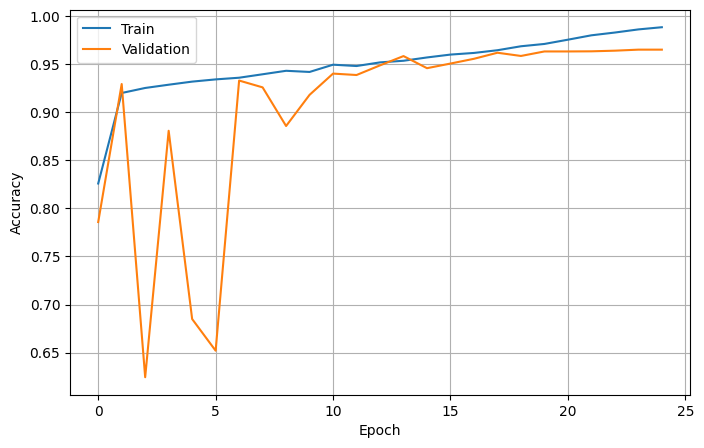

In [91]:
plt.figure(figsize=(8,5))

plt.plot(history["accuracy"], label="Train")
plt.plot(history["val_accuracy"], label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

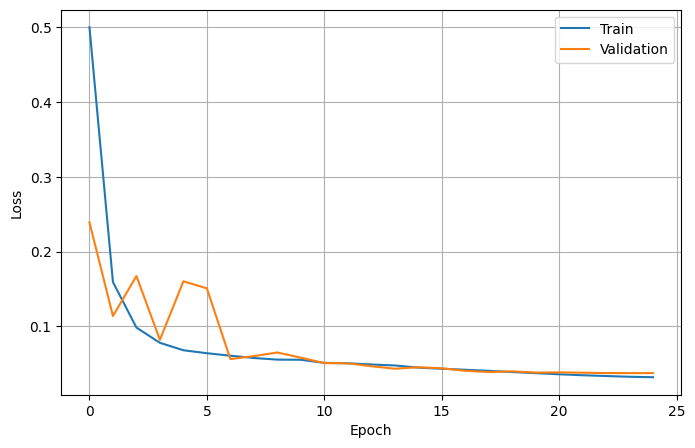

In [92]:
plt.figure(figsize=(8,5))

plt.plot(history["loss"], label="Train")
plt.plot(history["val_loss"], label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [93]:
history.to_csv("training_history_v2.csv", index=False)

234/234 ━━━━━━━━━━━━━━━━━━━━ 123s 505ms/step
MODEL PERFORMANCE
Accuracy : 0.9649
Precision: 0.9650
Recall   : 0.9649
F1-Score : 0.9650
CLASSIFICATION REPORT
              precision    recall  f1-score   support

        AFIB     0.9394    0.9445    0.9420      1478
        GSVT     0.9359    0.9411    0.9385      1256
          SB     0.9880    0.9873    0.9877      3162
          SR     0.9661    0.9581    0.9621      1576

    accuracy                         0.9649      7472
   macro avg     0.9573    0.9578    0.9575      7472
weighted avg     0.9650    0.9649    0.9650      7472



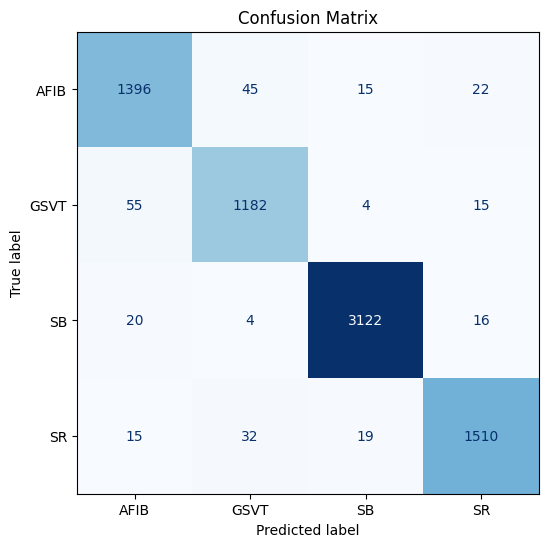

In [94]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)
class_names = ["AFIB", "GSVT", "SB", "SR"]

y_prob = model.predict(test_dataset, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

y_true = np.concatenate(
    [labels.numpy() for _, labels in test_dataset],
    axis=0
)

if len(y_true.shape) > 1:
    y_true = np.argmax(y_true, axis=1)

print("MODEL PERFORMANCE")

print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred, average='weighted'):.4f}")
print(f"Recall   : {recall_score(y_true, y_pred, average='weighted'):.4f}")
print(f"F1-Score : {f1_score(y_true, y_pred, average='weighted'):.4f}")

print("CLASSIFICATION REPORT")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

ax.set_title("Confusion Matrix")
ax.grid(False)

# Save Figure
fig.savefig(
    FIGURE_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

In [95]:
import pandas as pd

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    REPORT_DIR / "confusion_matrix.csv"
)

In [96]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

In [97]:
y_prob = best_model.predict(test_dataset, verbose=1)

y_true = np.concatenate(
    [y.numpy() for _, y in test_dataset]
)

y_true = np.argmax(y_true, axis=1)
n_classes = y_prob.shape[1]

y_true_bin = label_binarize(
    y_true,
    classes=np.arange(n_classes)
)

class_names = ["AFIB", "GSVT", "SB", "SR"]

fpr = {}
tpr = {}
roc_auc = {}

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

234/234 ━━━━━━━━━━━━━━━━━━━━ 124s 529ms/step


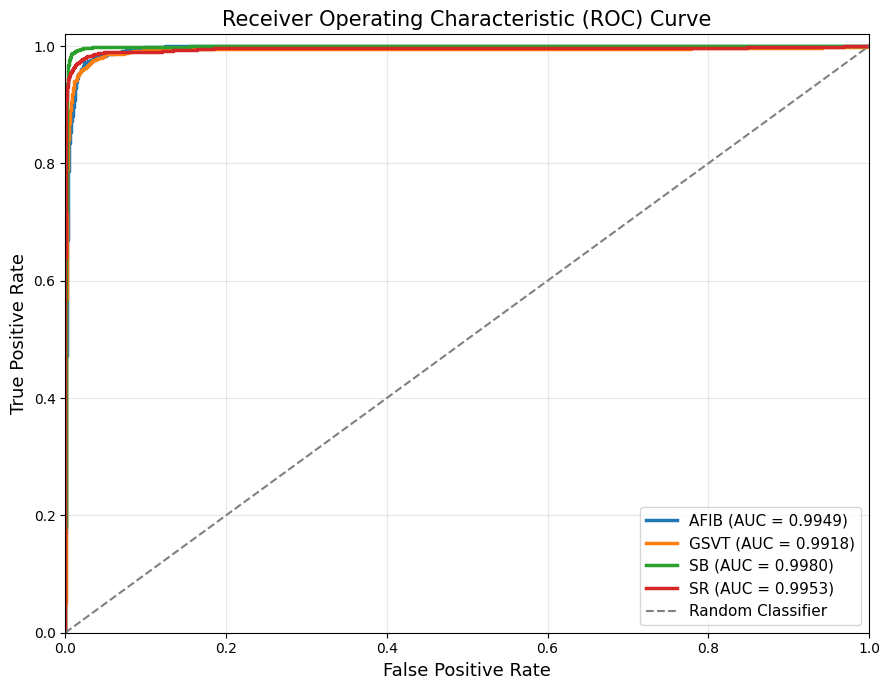

In [98]:
plt.figure(figsize=(9, 7))

for i in range(n_classes):
    plt.plot(
        fpr[i],
        tpr[i],
        linewidth=2.5,
        label=f"{class_names[i]} (AUC = {roc_auc[i]:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlim([0, 1])
plt.ylim([0, 1.02])

plt.xlabel("False Positive Rate", fontsize=13)
plt.ylabel("True Positive Rate", fontsize=13)
plt.title("Receiver Operating Characteristic (ROC) Curve", fontsize=15)

plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [99]:
import pandas as pd
roc_df = pd.DataFrame({
    "Class": class_names,
    "AUC": [roc_auc[i] for i in range(n_classes)]
})
roc_df.to_csv(
    REPORT_DIR / "roc_auc_scores.csv",
    index=False
)
roc_df

,Class,AUC
0,AFIB,0.994901
1,GSVT,0.991827
2,SB,0.998010
3,SR,0.995260


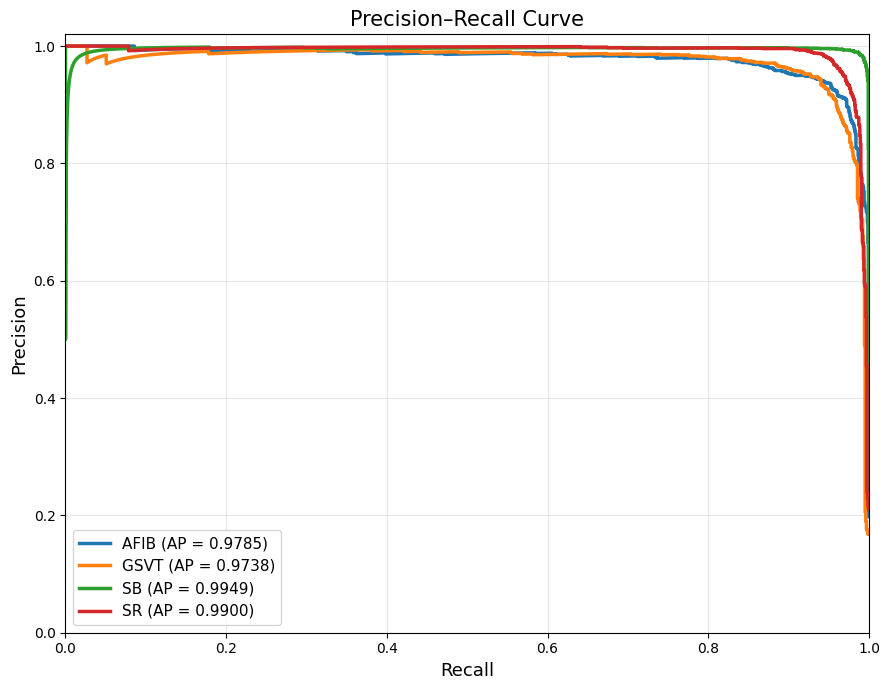

,Class,Average Precision
0,AFIB,0.978525
1,GSVT,0.973772
2,SB,0.994918
3,SR,0.989982


In [100]:
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import label_binarize
y_true_bin = label_binarize(
    y_true,
    classes=np.arange(len(class_names))
)

precision = {}
recall = {}
average_precision = {}

for i in range(len(class_names)):
    precision[i], recall[i], _ = precision_recall_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    average_precision[i] = average_precision_score(
        y_true_bin[:, i],
        y_prob[:, i]
    )

plt.figure(figsize=(9, 7))

for i in range(len(class_names)):
    plt.plot(
        recall[i],
        precision[i],
        linewidth=2.5,
        label=f"{class_names[i]} (AP = {average_precision[i]:.4f})"
    )

plt.xlabel("Recall", fontsize=13)
plt.ylabel("Precision", fontsize=13)
plt.title("Precision–Recall Curve", fontsize=15)

plt.xlim([0, 1])
plt.ylim([0, 1.02])

plt.grid(alpha=0.3)
plt.legend(loc="lower left", fontsize=11)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

pr_df = pd.DataFrame({
    "Class": class_names,
    "Average Precision": [
        average_precision[i]
        for i in range(len(class_names))
    ]
})

pr_df.to_csv(
    REPORT_DIR / "precision_recall_scores.csv",
    index=False
)

pr_df


## Phase 12 — Error Analysis

### Objective

Analyze misclassified ECG recordings from the test dataset to identify difficult classification cases and understand the model's prediction behavior.

### Analysis

The misclassified samples are examined by comparing their true labels, predicted labels, and prediction confidence. This analysis helps identify cases with similar or overlapping rhythm characteristics and provides insight into potential sources of classification error.

The selected misclassified samples are subsequently used for Grad-CAM visualization to examine the regions of the ECG spectrogram that contributed to the model's predictions.

In [101]:
import pandas as pd
import numpy as np

confidence = np.max(y_prob, axis=1)

misclassified = np.where(y_true != y_pred)[0]

error_df = pd.DataFrame({
    "Sample Index": misclassified,
    "True Label": [class_names[y_true[i]] for i in misclassified],
    "Predicted Label": [class_names[y_pred[i]] for i in misclassified],
    "Confidence": [confidence[i] for i in misclassified]
})

error_df

,Sample Index,True Label,Predicted Label,Confidence
0,10,AFIB,GSVT,0.727981
1,11,SR,AFIB,0.772638
2,13,AFIB,GSVT,0.639018
3,25,GSVT,AFIB,0.691107
4,62,SR,GSVT,0.607576
...,...,...,...,...
257,7353,GSVT,AFIB,0.749660
258,7367,GSVT,AFIB,0.705405
259,7372,GSVT,SR,0.541722
260,7460,GSVT,SB,0.638692


In [102]:
error_df.to_csv(
    REPORT_DIR / "error_analysis.csv",
    index=False
)

print(f"Misclassified Samples : {len(error_df)}")
print(f"Correct Predictions   : {len(y_true)-len(error_df)}")
print(f"Total Test Samples    : {len(y_true)}")

Misclassified Samples : 262
Correct Predictions   : 7210
Total Test Samples    : 7472


In [103]:
error_df.sort_values(
    by="Confidence",
    ascending=False
).head(20)

,Sample Index,True Label,Predicted Label,Confidence
111,2974,GSVT,SB,0.797732
216,5989,AFIB,GSVT,0.792799
247,6969,SR,GSVT,0.788771
137,3533,SR,AFIB,0.786859
179,4756,SR,SB,0.786474
132,3414,GSVT,SB,0.783931
240,6655,SR,SB,0.783611
27,641,SR,SB,0.783343
166,4409,SB,SR,0.783099
74,1870,AFIB,GSVT,0.782101


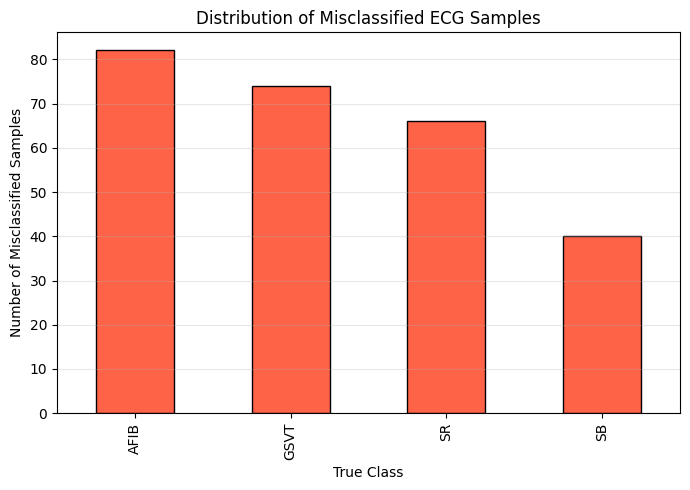

In [104]:
import matplotlib.pyplot as plt

counts = error_df["True Label"].value_counts()

plt.figure(figsize=(7,5))

counts.plot(
    kind="bar",
    color="tomato",
    edgecolor="black"
)

plt.ylabel("Number of Misclassified Samples")
plt.xlabel("True Class")
plt.title("Distribution of Misclassified ECG Samples")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "error_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [105]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import gc

In [110]:
last_conv_layer = None

for layer in reversed(best_model.layers):
    try:
        if len(layer.output.shape) == 4:
            last_conv_layer = layer.name
            break
    except:
        continue

print("Last Conv Layer:", last_conv_layer)

Last Conv Layer: multiply_3


In [111]:
grad_model = tf.keras.Model(
    inputs=best_model.input,
    outputs=[
        best_model.get_layer(last_conv_layer).output,
        best_model.output
    ]
)

In [121]:
def generate_gradcam(image):

    img = tf.expand_dims(image, axis=0)

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(img, training=False)

        class_idx = tf.argmax(predictions[0])

        loss = predictions[:, class_idx]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)

    heatmap = tf.maximum(heatmap, 0)

    heatmap /= (tf.reduce_max(heatmap) + 1e-10)

    heatmap = heatmap.numpy()

    del grads
    del pooled_grads
    del conv_outputs

    gc.collect()

    return heatmap

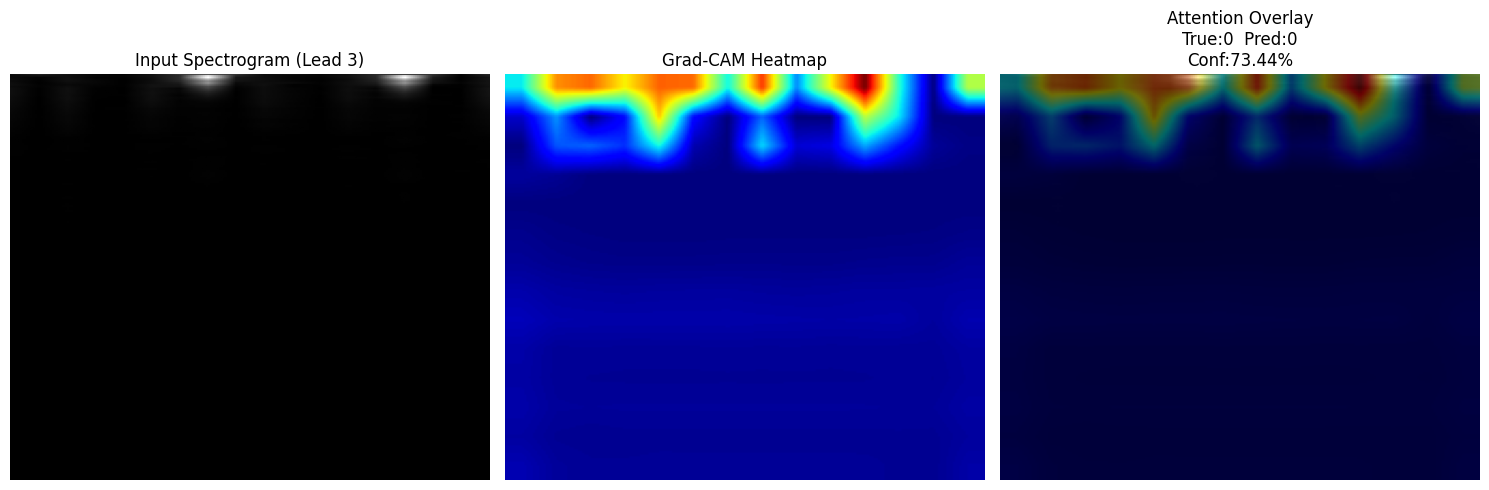

7416

In [128]:
import gc
import cv2
import matplotlib.pyplot as plt
import numpy as np

images, labels = next(iter(test_dataset))
idx = 15
image = images[idx]
true_label = tf.argmax(labels[idx]).numpy()
prediction = best_model.predict(
    image[None],
    verbose=0
)
pred_label = np.argmax(prediction)

confidence = np.max(prediction)
heatmap = generate_gradcam(image)

heatmap = cv2.resize(
    heatmap,
    (224,224)
)

heatmap_color = cv2.applyColorMap(
    np.uint8(255*heatmap),
    cv2.COLORMAP_JET
)

lead = 2

spectrogram = image[:,:,lead].numpy()

spectrogram = (
    spectrogram - spectrogram.min()
) / (
    spectrogram.max()-spectrogram.min()+1e-10
)

spectrogram_uint8 = np.uint8(
    spectrogram*255
)

overlay = cv2.addWeighted(
    cv2.cvtColor(
        spectrogram_uint8,
        cv2.COLOR_GRAY2BGR
    ),
    0.6,
    heatmap_color,
    0.4,
    0
)

plt.figure(figsize=(15,5))

plt.subplot(131)
plt.imshow(
    spectrogram,
    cmap="gray",
    aspect="auto"
)
plt.title(f"Input Spectrogram (Lead {lead+1})")
plt.axis("off")

plt.subplot(132)
plt.imshow(
    heatmap,
    cmap="jet",
    aspect="auto"
)
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(133)
plt.imshow(
    cv2.cvtColor(
        overlay,
        cv2.COLOR_BGR2RGB
    ),
    aspect="auto"
)
plt.title(
    f"Attention Overlay\nTrue:{true_label}  Pred:{pred_label}\nConf:{confidence:.2%}"
)
plt.axis("off")
plt.savefig(
    "gradcam_sample_03.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()

plt.show()

del prediction
del heatmap
del heatmap_color
del overlay
del spectrogram
del spectrogram_uint8

gc.collect()

# Final Summary

This notebook presents the complete workflow for ECG arrhythmia classification using a Hybrid CNN–CBAM–Transformer architecture.

### Workflow

1. **Dataset Preparation** — ECG metadata and diagnosis labels were standardized using the official SNOMED-CT mapping.
2. **Class Selection** — Diagnosis categories were consolidated and encoded for supervised classification.
3. **Signal Preprocessing** — 12-lead ECG recordings were converted into standardized STFT spectrogram representations.
4. **Dataset Pipeline** — Training and testing datasets were prepared using a TensorFlow data pipeline with on-the-fly spectrogram generation and augmentation.
5. **Model Development** — A hybrid architecture combining Residual CNN blocks, CBAM attention, positional embedding, and Transformer Encoder blocks was developed.
6. **Model Training** — The model was trained using class-balanced weights and configured callbacks for checkpointing, early stopping, and training-history logging.
7. **Model Evaluation** — Performance was assessed using test metrics, classification analysis, confusion matrix, ROC/AUC, and Precision–Recall analysis.
8. **Error Analysis and Interpretability** — Misclassified samples were analyzed using prediction confidence and Grad-CAM visualizations to examine the model's decision-making behavior.

### Final Outputs

The notebook produces the trained model, training history, quantitative evaluation results, performance figures, error-analysis results, and Grad-CAM visualizations used to assess the proposed approach.

---

**End of Notebook**